# Greedy Multi-Start Investment Analysis

This notebook runs ten Draft 2 greedy-search runs (period 0), each from a
different seeded 16-link starting topology. It compares building new links with
upgrading existing links and examines how selected investments relate to
pre-investment prices, quantities, endpoint areas, cost, and investment order.

**Units:** prices are EUR/MWh, quantities MW, welfare EUR/h, and capital costs
million GBP. A single period's welfare flow and upfront capital cost are not
directly comparable. This report's gain-per-cost statistic is descriptive only;
it is not a financial return.

The first code cell runs the original model's greedy search for all ten starting
networks. This can take a while. Results remain in memory; no separate JSON or
HTML report file is created.


In [ ]:
%matplotlib inline
from contextlib import redirect_stdout
from io import StringIO
import json
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = PROJECT_DIR / "D2A_Project_Draft_2"
if not (PROJECT_DIR / "data").is_dir():
    raise FileNotFoundError("Open this notebook from the repository or Draft 2 project folder.")
os.chdir(PROJECT_DIR)
SOURCE_NOTEBOOK = PROJECT_DIR / "d2a_draft_2.ipynb"
with SOURCE_NOTEBOOK.open(encoding="utf-8") as source_file:
    source_cells = json.load(source_file)["cells"]
source_by_id = {
    cell.get("id"): "".join(cell.get("source", []))
    for cell in source_cells if cell.get("cell_type") == "code"
}
cell_ids = (
    "eb864047", "36b1ab86", "9da957b8", "19a67f39",
    "528c5d35", "b428c02f", "fc3b44d1",
)
if set(cell_ids) - source_by_id.keys():
    raise ValueError("The expected market or model cells are missing from Draft 2.")
model = {"__name__": "_multistart_analysis"}
for cell_id in cell_ids:
    source = source_by_id[cell_id]
    if cell_id == "eb864047":
        source = source.replace("from IPython.display import display", "")
        model["display"] = lambda value=None, **kwargs: None
    if cell_id == "fc3b44d1":
        marker = "RUN_GREEDY_SEARCH = True\nif RUN_GREEDY_SEARCH:"
        if marker not in source:
            raise ValueError("Could not isolate Draft 2 greedy-search function.")
        source = source.split(marker, 1)[0]
    exec(compile(source, f"{SOURCE_NOTEBOOK.name}:{cell_id}", "exec"), model)

period_data = model["period_data"]
base_network = model["INTERCONNECTORS"].reset_index(drop=True).copy()
nodes = sorted(period_data)
RUN_COUNT, START_EDGE_COUNT, SEED_BASE = 10, 16, 20261004

def sampled_network(seed):
    def find(parent, node):
        while parent[node] != node:
            parent[node] = parent[parent[node]]
            node = parent[node]
        return node
    def union(parent, left, right):
        left_root, right_root = find(parent, left), find(parent, right)
        if left_root == right_root:
            return False
        parent[left_root] = right_root
        return True
    parent = {node: node for node in nodes}
    for edge in base_network.itertuples(index=False):
        union(parent, str(edge.from_market), str(edge.to_market))
    component = {node: find(parent, node) for node in nodes}
    min_edges = len(nodes) - len(set(component.values()))
    if START_EDGE_COUNT < min_edges or START_EDGE_COUNT > len(base_network):
        raise ValueError("Cannot sample requested starting-network size.")
    rng = random.Random(seed)
    order = list(range(len(base_network)))
    rng.shuffle(order)
    forest = {node: node for node in nodes}
    chosen = []
    for index in order:
        edge = base_network.iloc[index]
        if union(forest, str(edge.from_market), str(edge.to_market)):
            chosen.append(index)
    remaining = [index for index in order if index not in set(chosen)]
    chosen.extend(rng.sample(remaining, START_EDGE_COUNT - len(chosen)))
    sample = base_network.iloc[chosen].copy().reset_index(drop=True)
    for edge in sample.itertuples(index=False):
        union(forest, str(edge.from_market), str(edge.to_market))
    sampled_component = {node: find(forest, node) for node in nodes}
    if any(
        (component[a] == component[b]) != (sampled_component[a] == sampled_component[b])
        for a in nodes for b in nodes
    ):
        raise AssertionError("Sample does not preserve baseline components.")
    return sample

run_summary, before_rows, after_rows, action_rows = [], [], [], []
seen_starts = set()
for run in range(1, RUN_COUNT + 1):
    seed = SEED_BASE + run - 1
    start = sampled_network(seed)
    initial_connections = sorted(
        f"{edge.from_market} -- {edge.to_market}"
        for edge in start.itertuples(index=False)
    )
    print(f"Run {run} initial network ({len(initial_connections)} connections):")
    print("  " + "\n  ".join(initial_connections))
    start_edges = frozenset(
        tuple(sorted((str(e.from_market), str(e.to_market))))
        for e in start.itertuples(index=False)
    )
    if start_edges in seen_starts:
        raise AssertionError("Duplicate starting topology.")
    seen_starts.add(start_edges)
    start_solution = model["solve_market"](
        period_data, start, model_name=f"analysis_{run}_starting", diagnostics=True
    )
    initial_welfare = float(start_solution["welfare"])
    before_rows.extend(
        {"run": run, "seed": seed, **row}
        for row in start_solution["nodes"].to_dict("records")
    )
    with redirect_stdout(StringIO()):
        result = model["greedy_investment_search"](
            period_data, start,
            budget_multiplier=model["BUDGET_MULTIPLIER"],
            max_iterations=model["MAX_GREEDY_ITERATIONS"],
            min_surplus_gain=model["MIN_SURPLUS_GAIN"],
        )
    history = result["history"]
    final_network = result["interconnectors"].reset_index(drop=True)
    final_solution = model["solve_market"](
        period_data, final_network,
        model_name=f"analysis_{run}_final", diagnostics=True
    )
    final_welfare = float(final_solution["welfare"])
    after_rows.extend(
        {"run": run, "seed": seed, **row}
        for row in final_solution["nodes"].to_dict("records")
    )
    action_rows.extend(
        {"run": run, "seed": seed, **row}
        for row in history.to_dict("records")
    )
    run_summary.append({
        "run": run, "seed": seed, "starting_edges": len(start),
        "actions_selected": len(history),
        "initial_welfare_eur_per_h": initial_welfare,
        "final_welfare_eur_per_h": final_welfare,
        "welfare_gain_eur_per_h": final_welfare - initial_welfare,
        "investment_spent_million_gbp": float(result["spent"]),
        "investment_budget_million_gbp": float(result["budget"]),
    })
    print(
        f"Completed run {run}/{RUN_COUNT}: {len(history)} actions, "
        f"welfare gain {final_welfare - initial_welfare:,.0f} EUR/h"
    )

nodes_before, nodes_after = pd.DataFrame(before_rows), pd.DataFrame(after_rows)
runs, action_rows = pd.DataFrame(run_summary), action_rows
actions_raw = pd.DataFrame(action_rows)
counts, ranks = {}, {}
for row in action_rows:
    key = (row["action_type"], row["edge"])
    counts[key] = counts.get(key, 0) + 1
    ranks.setdefault(key, []).append(int(row["iteration"]))
commonality_records = [
    {
        "action_type": kind, "edge": edge, "runs_selected": count,
        "selection_rate": count / RUN_COUNT,
        "mean_selection_iteration": float(np.mean(ranks[(kind, edge)])),
    }
    for (kind, edge), count in sorted(counts.items(), key=lambda item: (-item[1], item[0]))
]
results = {
    "method": {"source_notebook": SOURCE_NOTEBOOK.name, "runs": RUN_COUNT},
    "investment_actions": action_rows,
    "preinvestment_nodes": before_rows,
    "final_nodes": after_rows,
    "run_summary": run_summary,
    "investment_commonality": commonality_records,
}

node_lookup = {
    (int(row.run), str(row.market)): row
    for row in nodes_before.itertuples(index=False)
}
endpoint_rows = []
for action in action_rows:
    left, right = [part.strip() for part in action["edge"].split(" -- ")]
    a, b = node_lookup[(int(action["run"]), left)], node_lookup[(int(action["run"]), right)]
    endpoint_rows.append({
        **action, "market_a": left, "market_b": right,
        "endpoint_mean_price": (a.nodal_price_eur_per_mwh + b.nodal_price_eur_per_mwh) / 2,
        "endpoint_price_gap": abs(a.nodal_price_eur_per_mwh - b.nodal_price_eur_per_mwh),
        "endpoint_supply": a.supply_mw + b.supply_mw,
        "endpoint_demand": a.demand_mw + b.demand_mw,
        "gain_per_cost": action["welfare_gain_eur_per_h"] / action["investment_cost_million_gbp"],
    })
actions = pd.DataFrame(endpoint_rows)
actions["action_type"] = pd.Categorical(
    actions["action_type"], categories=["build", "upgrade"], ordered=True
)
action_summary = actions.groupby("action_type", observed=False).agg(
    selected_actions=("action", "size"), distinct_edges=("edge", "nunique"),
    median_gain_eur_per_h=("welfare_gain_eur_per_h", "median"),
    mean_gain_eur_per_h=("welfare_gain_eur_per_h", "mean"),
    median_cost_million_gbp=("investment_cost_million_gbp", "median"),
    mean_cost_million_gbp=("investment_cost_million_gbp", "mean"),
    median_gain_per_cost=("gain_per_cost", "median"),
)
endpoints = actions.melt(
    id_vars=["run", "action_type"], value_vars=["market_a", "market_b"],
    value_name="market",
)
area_counts = endpoints.pivot_table(
    index="market", columns="action_type", values="run",
    aggfunc="size", fill_value=0, observed=False,
).reindex(columns=["build", "upgrade"], fill_value=0)
area_conditions = nodes_before.groupby("market").agg(
    mean_price=("nodal_price_eur_per_mwh", "mean"),
    mean_supply=("supply_mw", "mean"), mean_demand=("demand_mw", "mean"),
)
area_summary = area_conditions.join(area_counts).fillna(0)
area_summary["total_investment_endpoints"] = area_summary["build"] + area_summary["upgrade"]
area_summary = area_summary.sort_values("total_investment_endpoints", ascending=False)
print(f"Search complete: {len(actions)} selected actions. Results are held in memory.")

actions = pd.DataFrame(results["investment_actions"])
nodes_before = pd.DataFrame(results["preinvestment_nodes"])
nodes_after = pd.DataFrame(results["final_nodes"])
runs = pd.DataFrame(results["run_summary"])
commonality = pd.DataFrame(results["investment_commonality"])

node_lookup = {
    (int(row.run), str(row.market)): row
    for row in nodes_before.itertuples(index=False)
}
endpoint_rows = []
for action in actions.to_dict("records"):
    left, right = [part.strip() for part in action["edge"].split(" -- ")]
    a = node_lookup[(int(action["run"]), left)]
    b = node_lookup[(int(action["run"]), right)]
    endpoint_rows.append({
        **action,
        "market_a": left,
        "market_b": right,
        "endpoint_mean_price": (a.nodal_price_eur_per_mwh + b.nodal_price_eur_per_mwh) / 2,
        "endpoint_price_gap": abs(a.nodal_price_eur_per_mwh - b.nodal_price_eur_per_mwh),
        "endpoint_supply": a.supply_mw + b.supply_mw,
        "endpoint_demand": a.demand_mw + b.demand_mw,
        "gain_per_cost": (
            action["welfare_gain_eur_per_h"] / action["investment_cost_million_gbp"]
        ),
    })
actions = pd.DataFrame(endpoint_rows)
actions["action_type"] = pd.Categorical(
    actions["action_type"], categories=["build", "upgrade"], ordered=True
)

action_summary = actions.groupby("action_type", observed=False).agg(
    selected_actions=("action", "size"),
    distinct_edges=("edge", "nunique"),
    median_gain_eur_per_h=("welfare_gain_eur_per_h", "median"),
    mean_gain_eur_per_h=("welfare_gain_eur_per_h", "mean"),
    median_cost_million_gbp=("investment_cost_million_gbp", "median"),
    mean_cost_million_gbp=("investment_cost_million_gbp", "mean"),
    median_gain_per_cost=("gain_per_cost", "median"),
)

endpoints = actions.melt(
    id_vars=["run", "action_type"],
    value_vars=["market_a", "market_b"],
    value_name="market",
)
area_counts = endpoints.pivot_table(
    index="market", columns="action_type", values="run",
    aggfunc="size", fill_value=0, observed=False,
).reindex(columns=["build", "upgrade"], fill_value=0)
area_conditions = nodes_before.groupby("market").agg(
    mean_price=("nodal_price_eur_per_mwh", "mean"),
    mean_supply=("supply_mw", "mean"),
    mean_demand=("demand_mw", "mean"),
)
area_summary = area_conditions.join(area_counts).fillna(0)
area_summary["total_investment_endpoints"] = area_summary["build"] + area_summary["upgrade"]
area_summary = area_summary.sort_values("total_investment_endpoints", ascending=False)

print(f"Loaded {len(runs)} runs, {len(actions)} selected actions, "
      f"and {len(nodes_before)} pre-investment market observations.")
print("All selected-action welfare gains are positive:",
      bool((actions["welfare_gain_eur_per_h"] > 0).all()))
display(runs[[
    "run", "actions_selected", "initial_welfare_eur_per_h",
    "final_welfare_eur_per_h", "welfare_gain_eur_per_h",
    "investment_spent_million_gbp",
]])


Project directory: /Users/gsims/Documents/GitHub/d2a_project/D2A_Project_Draft_2
Gurobi version: (12, 0, 3)
Loaded 13 markets.
Selected period 0: 2026-09-07T22:00:00Z to 2026-09-07T22:15:00Z
Physics assumptions: ρ=2.82e-08 Ω·m, r=0.015 m, V=400 kV, Imax=2000 A, PF=1.00
One conductor upgrade multiplies area and baseline transfer/thermal capacity by 2.00×.
Upgrade cost assumption: 0.640 million GBP/km.
Run 1 initial network (16 connections):
  AT -- DE-LU
  BALTIC -- FI
  BALTIC -- SE
  BE -- FR
  BE -- NL
  BG -- RO
  DE-LU -- DK
  DE-LU -- FR
  DE-LU -- NL
  DE-LU -- PL
  DK -- NO
  DK -- SE
  FI -- NO
  NO -- NL
  NO -- SE
  PL -- SE
Set parameter Username
Set parameter LicenseID to value 2858384
Academic license - for non-commercial use only - expires 2027-08-28


## 1. Build versus upgrade

Builds can deliver a larger absolute one-step welfare gain, while upgrades
usually have a smaller modeled upfront cost. The search itself maximizes
absolute EUR/h gain among affordable actions, not gain per unit of capital cost.


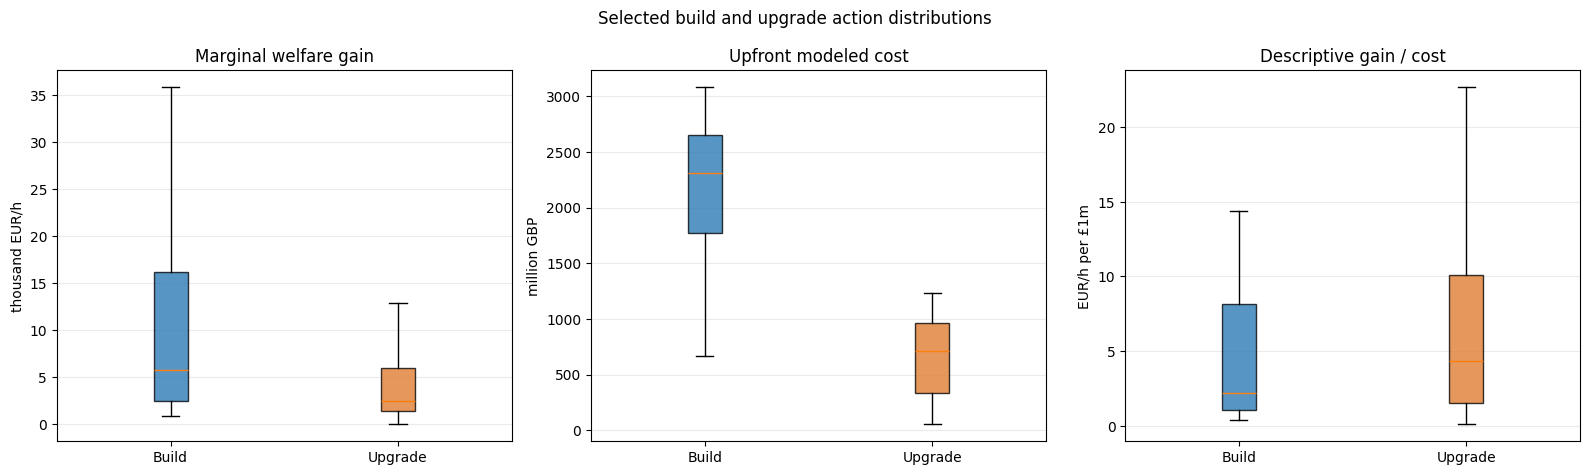

AttributeError: The '.style' accessor requires jinja2

In [ ]:
COLORS = {"build": "#2878B5", "upgrade": "#E07A2D"}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for axis, column, title, ylabel, scale in (
    (axes[0], "welfare_gain_eur_per_h", "Marginal welfare gain", "thousand EUR/h", 1_000),
    (axes[1], "investment_cost_million_gbp", "Upfront modeled cost", "million GBP", 1),
    (axes[2], "gain_per_cost", "Descriptive gain / cost", "EUR/h per £1m", 1),
):
    groups = [
        actions.loc[actions.action_type == kind, column].astype(float) / scale
        for kind in ("build", "upgrade")
    ]
    boxes = axis.boxplot(
        groups, tick_labels=["Build", "Upgrade"], patch_artist=True, showfliers=False
    )
    for box, kind in zip(boxes["boxes"], ("build", "upgrade")):
        box.set_facecolor(COLORS[kind])
        box.set_alpha(0.78)
    axis.set_title(title)
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", alpha=0.25)
fig.suptitle("Selected build and upgrade action distributions")
fig.tight_layout()
plt.show()

display(action_summary.reset_index().style.format({
    "median_gain_eur_per_h": "{:,.0f}",
    "mean_gain_eur_per_h": "{:,.0f}",
    "median_cost_million_gbp": "{:,.1f}",
    "mean_cost_million_gbp": "{:,.1f}",
    "median_gain_per_cost": "{:.2f}",
}))


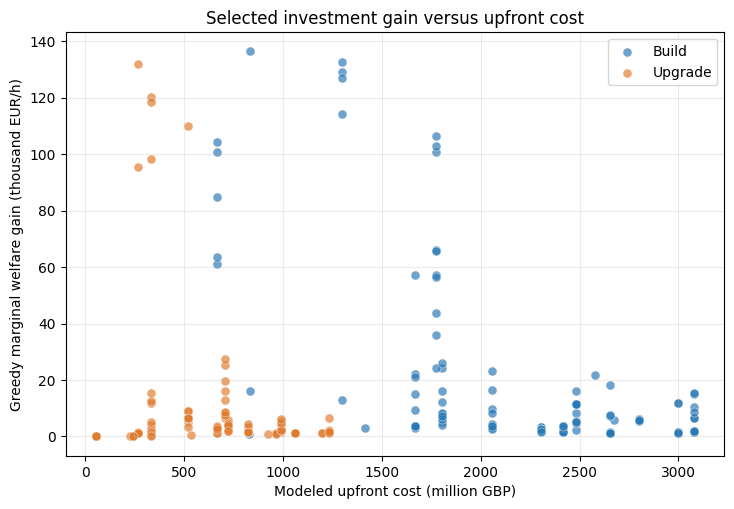

Spearman correlation (selected actions only):
  Cost: +0.08
  Pre-investment endpoint price gap: +0.05
  Mean pre-investment endpoint price: -0.07
  Combined endpoint supply: +0.39
  Combined endpoint demand: +0.38


In [ ]:
fig, axis = plt.subplots(figsize=(8.5, 5.5))
for kind in ("build", "upgrade"):
    group = actions.loc[actions.action_type == kind]
    axis.scatter(
        group.investment_cost_million_gbp,
        group.welfare_gain_eur_per_h / 1_000,
        label=kind.title(), color=COLORS[kind], alpha=0.68,
        s=42, edgecolors="white", linewidths=0.4,
    )
axis.set_xlabel("Modeled upfront cost (million GBP)")
axis.set_ylabel("Greedy marginal welfare gain (thousand EUR/h)")
axis.set_title("Selected investment gain versus upfront cost")
axis.legend()
axis.grid(alpha=0.25)
plt.show()

print("Spearman correlation (selected actions only):")
for field, label in (
    ("investment_cost_million_gbp", "Cost"),
    ("endpoint_price_gap", "Pre-investment endpoint price gap"),
    ("endpoint_mean_price", "Mean pre-investment endpoint price"),
    ("endpoint_supply", "Combined endpoint supply"),
    ("endpoint_demand", "Combined endpoint demand"),
):
    rho = actions["welfare_gain_eur_per_h"].corr(actions[field], method="spearman")
    print(f"  {label}: {rho:+.2f}")


## 2. Investment order and convergence

Starting networks change the first actions and their order. Compare the
cumulative greedy gain paths and spending paths across runs. These paths are
action sequences from different initial networks, so the same iteration number
does not represent an identical candidate set.


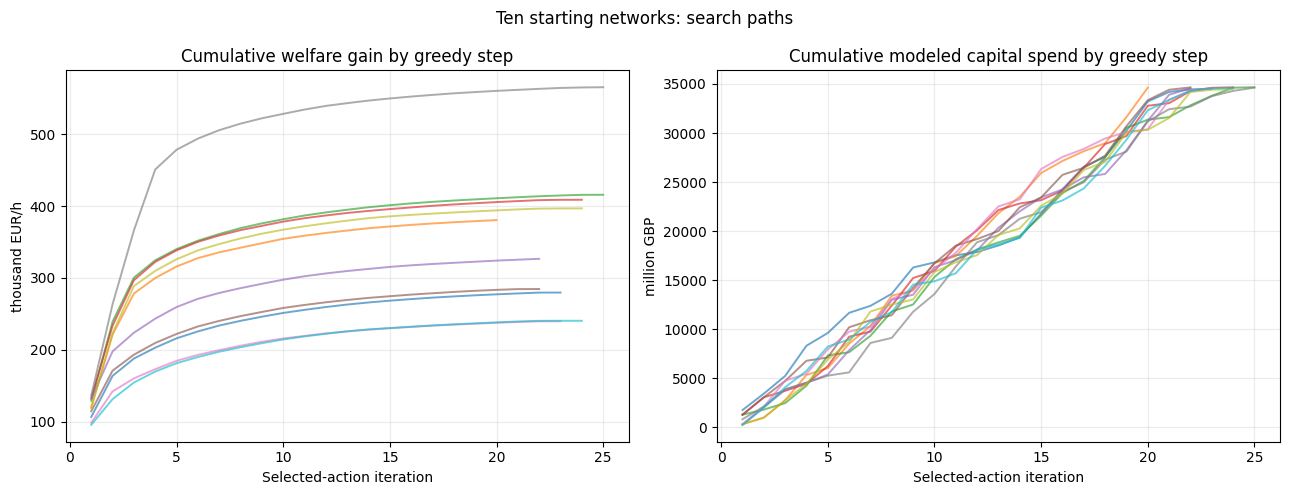

,run,action_type,edge,welfare_gain_eur_per_h
0,1,build,DE-LU -- FI,"106,459.744"
1,2,upgrade,DK -- SE,"120,404.136"
2,3,build,DE-LU -- SE,"129,031.123"
3,4,build,DE-LU -- SE,"132,692.208"
4,5,upgrade,NO -- SE,"131,786.582"
5,6,build,DE-LU -- SE,"114,400.104"
6,7,upgrade,DK -- SE,"98,377.766"
7,8,build,DK -- SE,"136,379.440"
8,9,upgrade,DK -- SE,"118,514.289"
9,10,upgrade,NO -- SE,"95,483.939"


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for run_id, group in actions.groupby("run", sort=True):
    group = group.sort_values("iteration")
    cumulative_gain = group.welfare_gain_eur_per_h.cumsum() / 1_000
    cumulative_spend = group.investment_cost_million_gbp.cumsum()
    axes[0].plot(group.iteration, cumulative_gain, alpha=0.65, linewidth=1.4)
    axes[1].plot(group.iteration, cumulative_spend, alpha=0.65, linewidth=1.4)
axes[0].set_title("Cumulative welfare gain by greedy step")
axes[0].set_ylabel("thousand EUR/h")
axes[1].set_title("Cumulative modeled capital spend by greedy step")
axes[1].set_ylabel("million GBP")
for axis in axes:
    axis.set_xlabel("Selected-action iteration")
    axis.grid(alpha=0.25)
fig.suptitle("Ten starting networks: search paths")
fig.tight_layout()
plt.show()

first_actions = (
    actions.sort_values("iteration").groupby("run", as_index=False).first()
)
display(first_actions[["run", "action_type", "edge", "welfare_gain_eur_per_h"]])


## 3. Which edge actions recur?

Each bar is one build or upgrade action (edge and action type); height is the
number of starting-network runs that selected it. Repeatedly upgrading a line
that was newly built is counted as a separate action.


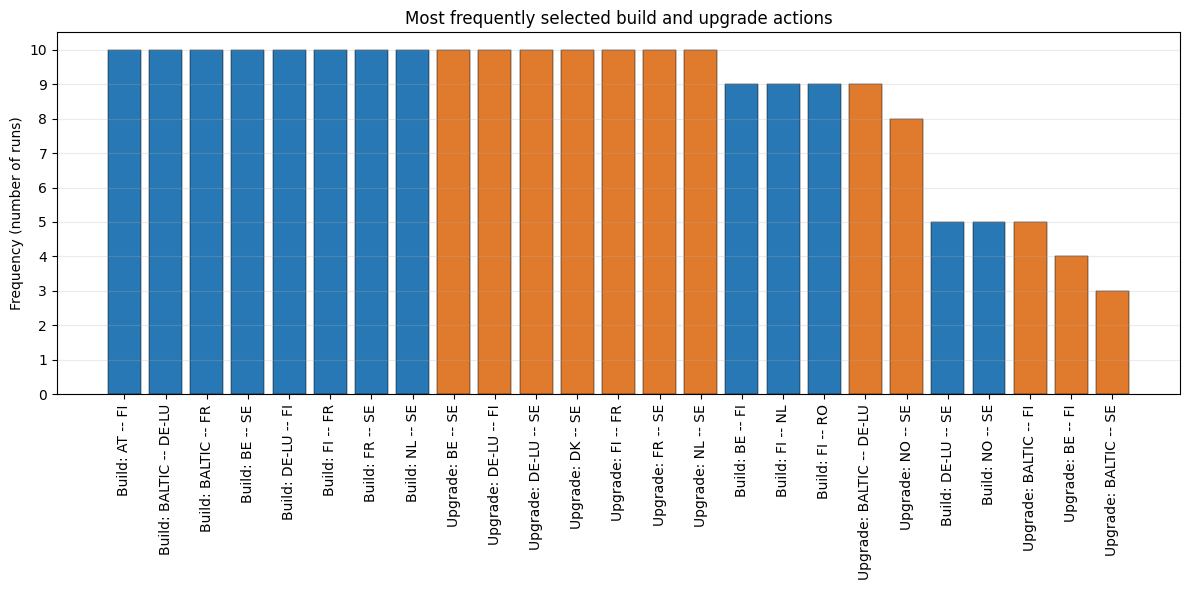

In [ ]:
commonality = commonality.copy()
commonality["action_label"] = (
    commonality["action_type"].astype(str).str.title() + ": " + commonality["edge"]
)
action_frequency = commonality.sort_values(
    ["runs_selected", "action_type", "edge"], ascending=[False, True, True]
).head(25)

fig, axis = plt.subplots(figsize=(max(12, 0.42 * len(action_frequency)), 6))
bar_colors = [COLORS[kind] for kind in action_frequency["action_type"].astype(str)]
axis.bar(
    range(len(action_frequency)), action_frequency["runs_selected"],
    color=bar_colors, edgecolor="black", linewidth=0.35,
)
axis.set_xticks(range(len(action_frequency)), action_frequency["action_label"], rotation=90)
axis.set_ylabel("Frequency (number of runs)")
axis.set_title("Most frequently selected build and upgrade actions")
axis.set_ylim(0, RUN_COUNT + 0.5)
axis.set_yticks(range(RUN_COUNT + 1))
axis.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()


## 4. Areas and pre-investment market conditions

Area involvement counts selected edge endpoints: each investment contributes
once to each endpoint. It is not a measure of investment value located inside
one market. Price and quantities are averages of the ten initial-network
clearing outcomes.


/var/folders/gx/5604lnb542v_zl7vr2mrv7f80000gn/T/ipykernel_8284/1915822328.py:31: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


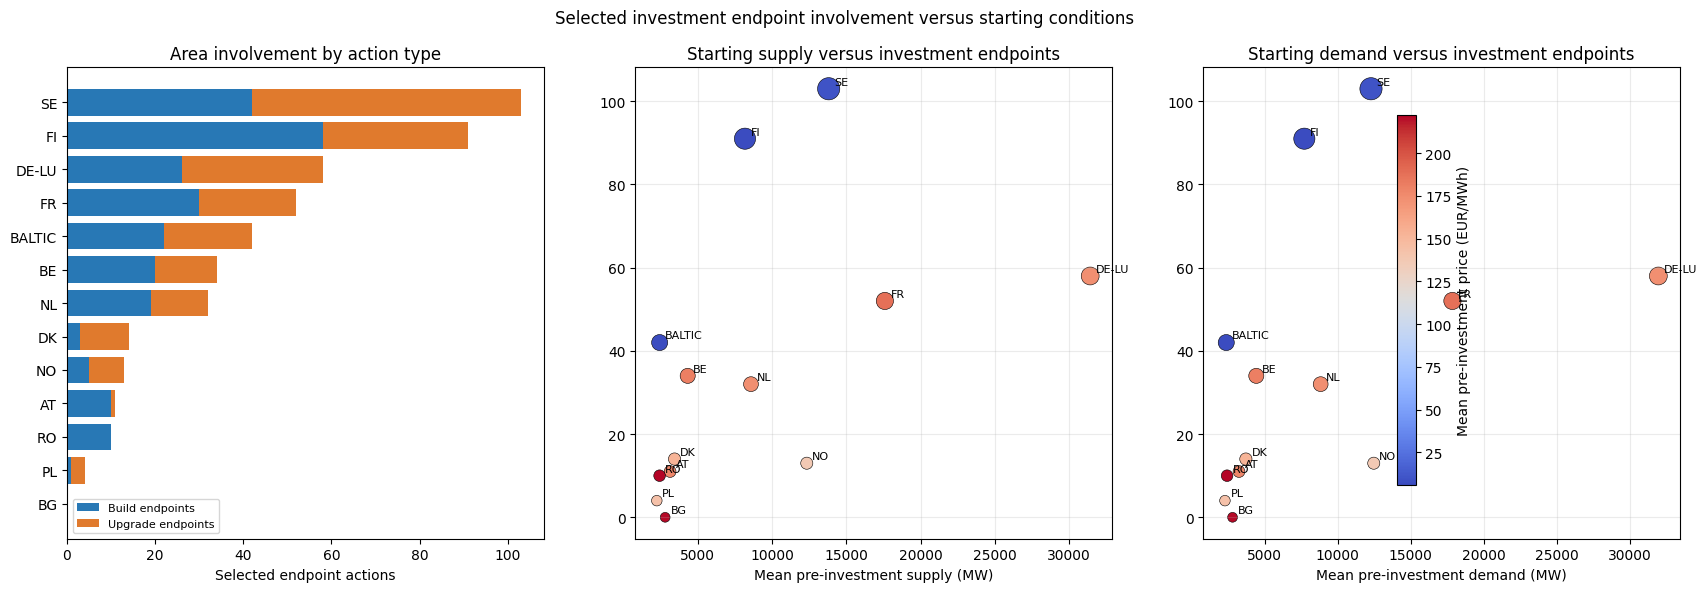

,market,mean_price_eur_per_mwh,mean_supply_mw,mean_demand_mw,build,upgrade,total_investment_endpoints
0,SE,9.962,"13,816.598","12,281.610",42.000,61.000,103.000
1,FI,6.109,"8,180.645","7,720.238",58.000,33.000,91.000
2,DE-LU,173.524,"31,422.132","31,947.508",26.000,32.000,58.000
3,FR,187.550,"17,600.206","17,855.073",30.000,22.000,52.000
4,BALTIC,6.427,"2,436.911","2,375.764",22.000,20.000,42.000
5,BE,181.582,"4,324.744","4,432.048",20.000,14.000,34.000
6,NL,173.953,"8,585.070","8,837.304",19.000,13.000,32.000
7,DK,152.918,"3,438.959","3,718.379",3.000,11.000,14.000
8,NO,137.716,"12,341.558","12,471.200",5.000,8.000,13.000
9,AT,177.538,"3,139.300","3,248.700",10.000,1.000,11.000


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6))
plot_areas = area_summary.sort_values("total_investment_endpoints")
axes[0].barh(plot_areas.index, plot_areas["build"], label="Build endpoints",
             color=COLORS["build"])
axes[0].barh(plot_areas.index, plot_areas["upgrade"], left=plot_areas["build"],
             label="Upgrade endpoints", color=COLORS["upgrade"])
axes[0].set_xlabel("Selected endpoint actions")
axes[0].set_title("Area involvement by action type")
axes[0].legend(fontsize=8)

for axis, quantity, title in (
    (axes[1], "mean_supply", "Starting supply"),
    (axes[2], "mean_demand", "Starting demand"),
):
    points = axis.scatter(
        area_summary[quantity],
        area_summary["total_investment_endpoints"],
        c=area_summary["mean_price"], cmap="coolwarm",
        s=50 + 2 * area_summary["total_investment_endpoints"],
        edgecolors="black", linewidths=0.4,
    )
    for area, row in area_summary.iterrows():
        axis.annotate(area, (row[quantity], row["total_investment_endpoints"]),
                      xytext=(4, 3), textcoords="offset points", fontsize=8)
    axis.set_xlabel(f"Mean pre-investment {quantity.removeprefix('mean_')} (MW)")
    axis.set_title(f"{title} versus investment endpoints")
    axis.grid(alpha=0.25)
colorbar = fig.colorbar(points, ax=axes[1:], shrink=0.8)
colorbar.set_label("Mean pre-investment price (EUR/MWh)")
fig.suptitle("Selected investment endpoint involvement versus starting conditions")
fig.tight_layout()
plt.show()

display(area_summary.reset_index().rename(columns={
    "index": "market", "mean_price": "mean_price_eur_per_mwh",
    "mean_supply": "mean_supply_mw", "mean_demand": "mean_demand_mw",
}))


## 5. Initial networks and investments

Each run has two side-by-side maps: the starting network, then the same network
with selected builds and upgrades added. Blue lines show starting connections,
green lines show new builds, and dashed orange lines show upgrades.


In [ ]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D

coordinates = model["MARKET_COORDINATES"]
missing_coordinates = set(nodes) - coordinates.keys()
if missing_coordinates:
    raise ValueError(f"Missing map coordinates for: {sorted(missing_coordinates)}")

label_offsets = {
    "AT": (0.45, -0.15), "BE": (-2.0, 0.35), "BALTIC": (0.5, 0.35),
    "BG": (0.45, -0.15), "DE-LU": (0.45, 0.35), "DK": (0.45, 0.35),
    "FI": (0.45, 0.35), "FR": (-1.9, -0.25), "NL": (0.45, 0.35),
    "NO": (0.45, 0.35), "PL": (0.45, -0.15), "RO": (0.45, -0.15),
    "SE": (0.45, 0.35),
}
projection = ccrs.PlateCarree()
fig, axes = plt.subplots(
    5, 4, figsize=(20, 23), subplot_kw={"projection": projection}
)


def style_map(axis):
    axis.set_extent([-12, 35, 35, 72], crs=projection)
    axis.add_feature(cfeature.OCEAN, facecolor="#F7F9FB", zorder=0)
    axis.add_feature(cfeature.LAND, facecolor="#E8EBEE", edgecolor="none", zorder=1)
    axis.add_feature(cfeature.BORDERS, edgecolor="#FFFFFF", linewidth=0.7, zorder=2)
    axis.add_feature(cfeature.COASTLINE, edgecolor="#AEB5BC", linewidth=0.6, zorder=3)

    for market in nodes:
        latitude, longitude = coordinates[market]
        axis.scatter(
            longitude, latitude, s=75, facecolor="#1F4E79", edgecolor="none",
            transform=projection, zorder=10,
        )
        dx, dy = label_offsets[market]
        axis.text(
            longitude + dx, latitude + dy, market, fontsize=8,
            fontweight="bold", color="#1F2933", transform=projection, zorder=11,
        )
    axis.axis("off")


def draw_edge(axis, edge, color, linestyle="-", linewidth=1.5, alpha=0.9):
    left, right = [market.strip() for market in edge.split(" -- ")]
    lat1, lon1 = coordinates[left]
    lat2, lon2 = coordinates[right]
    axis.plot(
        [lon1, lon2], [lat1, lat2], color=color, linestyle=linestyle,
        linewidth=linewidth, alpha=alpha, transform=projection, zorder=5,
    )


for run_id in range(1, RUN_COUNT + 1):
    row_index = (run_id - 1) // 2
    first_column = ((run_id - 1) % 2) * 2
    initial_axis = axes[row_index, first_column]
    invested_axis = axes[row_index, first_column + 1]
    style_map(initial_axis)
    style_map(invested_axis)

    initial_network = sampled_network(SEED_BASE + run_id - 1)
    run_actions = actions.loc[actions["run"] == run_id]
    for edge in initial_network.itertuples(index=False):
        label = f"{edge.from_market} -- {edge.to_market}"
        draw_edge(initial_axis, label, "#2878B5")
        draw_edge(invested_axis, label, "#2878B5")

    for edge in run_actions.loc[
        run_actions["action_type"].astype(str) == "build", "edge"
    ].drop_duplicates():
        draw_edge(invested_axis, edge, "#2A9D55", linewidth=2.0)
    for edge in run_actions.loc[
        run_actions["action_type"].astype(str) == "upgrade", "edge"
    ].drop_duplicates():
        draw_edge(invested_axis, edge, "#E07A2D", linestyle="--", linewidth=2.2)

    initial_axis.set_title(
        f"Run {run_id} | Initial network",
        fontsize=11, fontweight="bold", color="#17202A", pad=8,
    )
    invested_axis.set_title(
        f"Run {run_id} | Investments added",
        fontsize=11, fontweight="bold", color="#17202A", pad=8,
    )

legend_handles = [
    Line2D([0], [0], color="#2878B5", linewidth=2, label="Initial connection"),
    Line2D([0], [0], color="#2A9D55", linewidth=2, label="New build"),
    Line2D([0], [0], color="#E07A2D", linewidth=2, linestyle="--", label="Upgrade"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor="#1F4E79",
           markersize=7, label="Market centre"),
]
fig.legend(handles=legend_handles, loc="lower center", ncol=4, frameon=False)
fig.suptitle(
    "Initial and invested network for each run",
    fontsize=20, fontweight="bold", color="#17202A",
)
fig.tight_layout(rect=(0, 0.035, 1, 0.96), h_pad=0.8, w_pad=0.1)
display(fig)
plt.close(fig)


NameError: name 'model' is not defined

## Interpretation and limitations

- In these selected steps, builds produced higher median **absolute** marginal
  welfare gains; upgrades had lower modeled cost and higher median descriptive
  gain per £1m.
- This is consistent with the greedy objective: it maximizes absolute gain
  while respecting a capital budget, not a benefit-cost ratio.
- Selected action cost and gain have only a weak association in the chosen-action
  sample. This cannot establish that the search prefers cheap investments because
  gains for rejected candidates were not saved.
- Area involvement is greatest in areas that are endpoints of valuable network
  routes. The results show stronger descriptive association with market supply
  and demand than with price, but cannot separate quantity effects from topology,
  transfer limits, losses, or route cost.
- These are one-period results under illustrative assumptions. Comparing EUR/h
  against GBP upfront cost requires a currency conversion, asset life, discount
  rate, and a consistent benefit horizon before making investment-return claims.
